In [1]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional, Sequence


def plot(
    data,
    labels: Optional[Sequence[str]] = None,
    groups_axis: int = 0,
    title: str = "Box Plot",
    ylabel: str = "Dice",
    show_points: bool = False,
    figsize=(8, 6),
):
    """
    Plot box plots for a 2D array with mean, min, max, and variance boxes.

    Parameters
    ----------
    data : array-like, shape (n_groups, n_samples) or (n_samples, n_groups)
        Two-dimensional numerical data.

    labels : sequence of str, optional
        Label for each group.

    groups_axis : {0, 1}
        Axis representing separate groups:
        - 0: each row is one group
        - 1: each column is one group

    title : str
        Figure title.

    ylabel : str
        Y-axis label.

    show_points : bool
        Overlay individual data points.

    figsize : tuple
        Figure size.

    Notes
    -----
    The standard box represents the interquartile range, Q1 to Q3.
    The additional shaded variance box represents mean ± standard deviation.
    """

    data = np.asarray(data, dtype=float)

    if data.ndim != 2:
        raise ValueError(
            f"`data` must be a 2D array, but received shape {data.shape}."
        )

    if groups_axis not in (0, 1):
        raise ValueError("`groups_axis` must be either 0 or 1.")

    # Convert to shape: (number of groups, samples per group)
    groups = data if groups_axis == 0 else data.T

    n_groups = groups.shape[0]
    positions = np.arange(1, n_groups + 1)

    if labels is None:
        labels = [f"Group {i + 1}" for i in range(n_groups)]

    if len(labels) != n_groups:
        raise ValueError(
            f"Expected {n_groups} labels, but received {len(labels)}."
        )

    means = np.nanmean(groups, axis=1)
    minimums = np.nanmin(groups, axis=1)
    maximums = np.nanmax(groups, axis=1)
    variances = np.nanvar(groups, axis=1)
    standard_deviations = np.sqrt(variances)

    # Matplotlib boxplot expects one 1D array per group.
    valid_groups = [group[~np.isnan(group)] for group in groups]

    if any(group.size == 0 for group in valid_groups):
        raise ValueError("Every group must contain at least one non-NaN value.")

    fig, ax = plt.subplots(figsize=figsize)

    ax.boxplot(
        valid_groups,
        positions=positions,
        widths=0.5,
        patch_artist=True,
        showfliers=True,
    )

    # Mean ± standard deviation boxes
    variance_box_width = 0.28

    for x, mean, std, minimum, maximum in zip(
        positions,
        means,
        standard_deviations,
        minimums,
        maximums,
    ):
        # Shaded box extending from mean - std to mean + std
        ax.add_patch(
            plt.Rectangle(
                (x - variance_box_width / 2, mean - std),
                variance_box_width,
                2 * std,
                alpha=0.25,
                zorder=2,
            )
        )

        # Full min-to-max line
        ax.vlines(
            x,
            minimum,
            maximum,
            linestyles="dashed",
            linewidth=1.2,
            zorder=1,
        )

    # Mean markers
    ax.scatter(
        positions,
        means,
        marker="D",
        s=55,
        label="Mean",
        zorder=4,
    )

    # Minimum markers
    ax.scatter(
        positions,
        minimums,
        marker="v",
        s=55,
        label="Minimum",
        zorder=4,
    )

    # Maximum markers
    ax.scatter(
        positions,
        maximums,
        marker="^",
        s=55,
        label="Maximum",
        zorder=4,
    )

    if show_points:
        rng = np.random.default_rng(42)

        for x, group in zip(positions, valid_groups):
            jittered_x = rng.normal(x, 0.04, size=group.size)
            ax.scatter(
                jittered_x,
                group,
                s=20,
                alpha=0.5,
                zorder=3,
            )
    
    # ax.set_ylim(top=1)
    ax.set_xticks(positions)
    ax.set_xticklabels(labels, fontsize=16)
    # ax.set_title(title)
    ax.set_ylabel(ylabel, fontsize=16)
    ax.tick_params(labelsize=16)
    ax.grid(axis="y", alpha=0.25)
    # ax.legend()

    plt.tight_layout()
    plt.show()

    return fig, ax

In [11]:
data = [
    [0.7125, 0.7314, 0.7465, 0.7308, 0.7326],
]

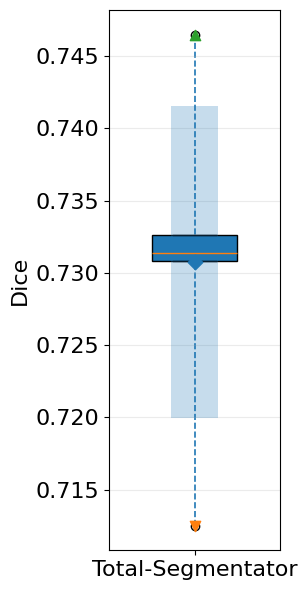

(<Figure size 300x600 with 1 Axes>, <Axes: ylabel='Dice'>)

In [13]:
plot(data, labels=["Total-Segmentator"], figsize=(3,6))